# Day 04 — Attention in LLMs: Hands-on Notebook

**Series:** LLM Inference Engineering  
**Audience:** Beginner-friendly, with practical Python  
**Goal:** See how attention scores, Softmax, causal masking, attention heads, KV-cache memory, scaling, and context length work.

## How to use this notebook

1. Open this notebook in VS Code.
2. Select your Python environment or `.venv` kernel.
3. Run the cells from top to bottom.
4. Read the explanation before running each code cell.


> This notebook uses small, made-up numbers so the calculations are easy to understand. It demonstrates the ideas; it is not loading or running a full language model.

## 0. Setup

We only need NumPy and Matplotlib for this lesson. If they are not installed in your selected environment, run the next cell.

In [12]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
print("NumPy version:", np.__version__)
print("Attention hands-on environment is ready.")

NumPy version: 2.4.6
Attention hands-on environment is ready.


**What this does:** NumPy handles vector and matrix calculations. Matplotlib draws the attention patterns.



## 1. Query, Key, and Value (Q, K, V)

A simple way to remember the roles:

- **Query:** What information am I looking for?
- **Key:** What information can this token match with?
- **Value:** What information will this token pass along?

In a real Transformer, learned weight matrices create Q, K, and V from token representations. Here, we use small illustrative vectors so we can focus on the calculation.

In [13]:
# Three toy token representations, each with two features.
tokens = np.array([
    [1.0, 0.0],  # token 1
    [0.0, 1.0],  # token 2
    [1.0, 1.0],  # token 3
])

# Small illustrative projection matrices.
W_Q = np.array([[1.0, 0.0], [0.0, 1.0]])
W_K = np.array([[1.0, 0.0], [0.0, 1.0]])
W_V = np.array([[1.0, 0.5], [0.5, 1.0]])

Q = tokens @ W_Q
K = tokens @ W_K
V = tokens @ W_V

print("Token representations (X):\n", tokens)
print("\nQueries (Q):\n", Q)
print("\nKeys (K):\n", K)
print("\nValues (V):\n", V)

Token representations (X):
 [[1. 0.]
 [0. 1.]
 [1. 1.]]

Queries (Q):
 [[1. 0.]
 [0. 1.]
 [1. 1.]]

Keys (K):
 [[1. 0.]
 [0. 1.]
 [1. 1.]]

Values (V):
 [[1.  0.5]
 [0.5 1. ]
 [1.5 1.5]]


**Explanation:** Matrix multiplication projects each token representation into Q, K, and V. Our projection matrices are intentionally simple; real models learn these matrices during training.



## 2. Attention scores

The first calculation compares every Query with every Key. A dot product gives a score. A larger score means a stronger match in this toy example.

Raw attention scores (Q times K transpose):
 [[1. 0. 1.]
 [0. 1. 1.]
 [1. 1. 2.]]


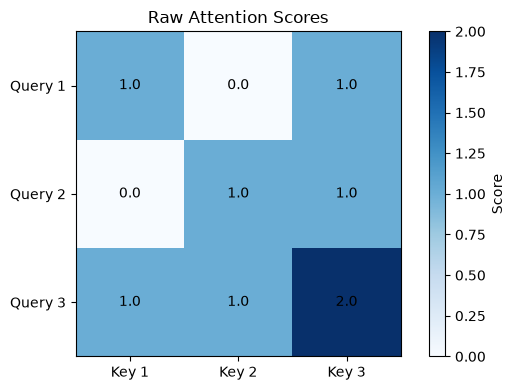

In [14]:
scores = Q @ K.T
print("Raw attention scores (Q times K transpose):\n", scores)

plt.figure(figsize=(6, 4))
plt.imshow(scores, cmap="Blues")
plt.colorbar(label="Score")
plt.xticks(range(3), ["Key 1", "Key 2", "Key 3"])
plt.yticks(range(3), ["Query 1", "Query 2", "Query 3"])
plt.title("Raw Attention Scores")
for i in range(scores.shape[0]):
    for j in range(scores.shape[1]):
        plt.text(j, i, f"{scores[i, j]:.1f}", ha="center", va="center")
plt.tight_layout()
plt.show()

**What to notice:** The matrix has one row for each Query and one column for each Key. Each cell shows how strongly that Query matches that Key.

 
“Now we compare every Query with every Key. The result is a score matrix. Each row belongs to one Query, and each column belongs to one Key. The scores tell us which tokens are more relevant to the current token.”

## 3. Softmax: scores become weights

Softmax converts scores into positive weights that add up to one in each row. We subtract the largest score before exponentiation to make the calculation more numerically stable.

Attention weights:
 [[0.422 0.155 0.422]
 [0.155 0.422 0.422]
 [0.212 0.212 0.576]]

Sum of each row: [1. 1. 1.]


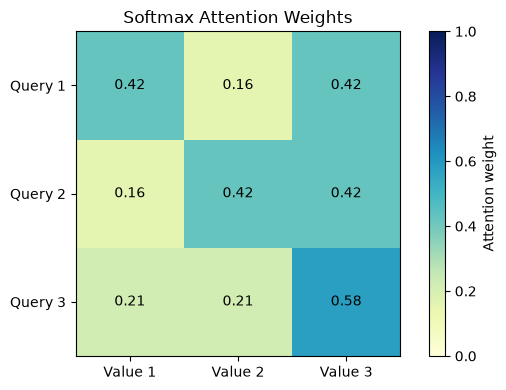

In [15]:
def softmax(x, axis=-1):
    x_shifted = x - np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x_shifted)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)

weights = softmax(scores, axis=1)
print("Attention weights:\n", weights)
print("\nSum of each row:", weights.sum(axis=1))

plt.figure(figsize=(6, 4))
plt.imshow(weights, cmap="YlGnBu", vmin=0, vmax=1)
plt.colorbar(label="Attention weight")
plt.xticks(range(3), ["Value 1", "Value 2", "Value 3"])
plt.yticks(range(3), ["Query 1", "Query 2", "Query 3"])
plt.title("Softmax Attention Weights")
for i in range(weights.shape[0]):
    for j in range(weights.shape[1]):
        plt.text(j, i, f"{weights[i, j]:.2f}", ha="center", va="center")
plt.tight_layout()
plt.show()

**What to notice:** Every weight is between zero and one, and each row adds up to one. A larger weight means that token's Value contributes more to the result.


“Softmax converts the raw scores into attention weights. Each row adds up to one, like percentages that total one hundred percent. A token with a larger weight contributes more information to the final attention output.”

## 4. Combine the Values

The attention output is the weighted sum of the Value vectors. The weights decide how much each Value contributes.

In [16]:
attention_output = weights @ V
print("Value vectors:\n", V)
print("\nAttention output:\n", attention_output)

Value vectors:
 [[1.  0.5]
 [0.5 1. ]
 [1.5 1.5]]

Attention output:
 [[1.133 1.   ]
 [1.    1.133]
 [1.182 1.182]]



“We now multiply the attention weights by the Value vectors. This creates a weighted combination of the information from the tokens. That is the central idea of attention: compare, assign weights, and combine information.”

## 5. Causal masking

For next-token generation, a token must not use future tokens. We block future positions by setting their scores to negative infinity before Softmax. Their resulting weights become zero.

Future-position mask (True means blocked):
 [[False  True  True]
 [False False  True]
 [False False False]]

Scores after causal mask:
 [[  1. -inf -inf]
 [  0.   1. -inf]
 [  1.   1.   2.]]

Weights after causal mask:
 [[1.    0.    0.   ]
 [0.269 0.731 0.   ]
 [0.212 0.212 0.576]]

Row sums: [1. 1. 1.]


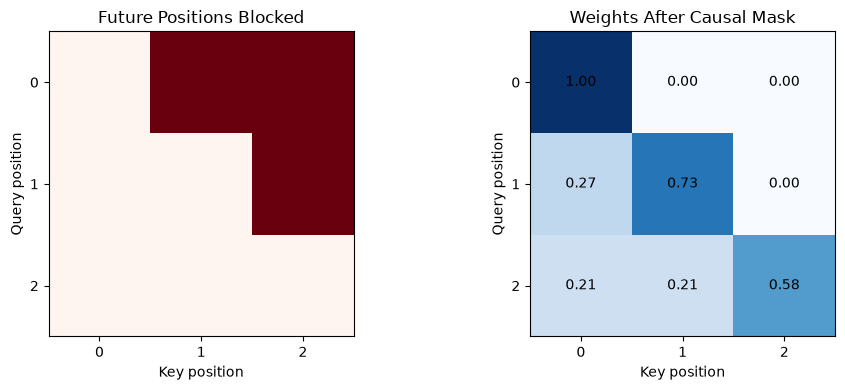

In [17]:
seq_len = scores.shape[0]
future_mask = np.triu(np.ones((seq_len, seq_len), dtype=bool), k=1)

masked_scores = scores.copy()
masked_scores[future_mask] = -np.inf
causal_weights = softmax(masked_scores, axis=1)

print("Future-position mask (True means blocked):\n", future_mask)
print("\nScores after causal mask:\n", masked_scores)
print("\nWeights after causal mask:\n", causal_weights)
print("\nRow sums:", causal_weights.sum(axis=1))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(future_mask, cmap="Reds")
plt.title("Future Positions Blocked")
plt.xlabel("Key position")
plt.ylabel("Query position")
plt.xticks(range(seq_len))
plt.yticks(range(seq_len))
plt.subplot(1, 2, 2)
plt.imshow(causal_weights, cmap="Blues", vmin=0, vmax=1)
plt.title("Weights After Causal Mask")
plt.xlabel("Key position")
plt.ylabel("Query position")
plt.xticks(range(seq_len))
plt.yticks(range(seq_len))
for i in range(seq_len):
    for j in range(seq_len):
        plt.text(j, i, f"{causal_weights[i,j]:.2f}", ha="center", va="center")
plt.tight_layout()
plt.show()

**What to notice:** The upper triangle is blocked. The first token can see only itself. The second can see the first and second. The third can see all three tokens.


“A causal mask blocks future tokens. We set future scores to minus infinity before Softmax, so their weights become zero. The first token sees only itself. The second sees the first and second. The third can see all three. This keeps next-token prediction in the correct order.”

## 6. Compare MHA, GQA, and MQA cache sizes

Multi-Head Attention (MHA) has a Key-Value head for each Query head. Grouped-Query Attention (GQA) shares Key-Value heads among groups of Query heads. Multi-Query Attention (MQA) uses one shared Key-Value head.

This simplified calculation assumes the same number of Query heads and the same head dimension across options.

In [18]:
query_heads = 8
head_dim = 128
num_layers = 32
bytes_per_value = 2  # e.g. 16-bit values

designs = {
    "MHA": 8,
    "GQA": 4,
    "MQA": 1,
}

def kv_cache_bytes_per_token(layers, kv_heads, dimension, bytes_per_value):
    # Factor 2 accounts for both Key and Value.
    return 2 * layers * kv_heads * dimension * bytes_per_value

for name, kv_heads in designs.items():
    per_token = kv_cache_bytes_per_token(
        num_layers, kv_heads, head_dim, bytes_per_value
    )
    print(f"{name}: KV heads={kv_heads}, cache/token={per_token:,} bytes, "
          f"relative to MHA={per_token / kv_cache_bytes_per_token(num_layers, 8, head_dim, bytes_per_value):.1%}")

context_tokens = 8192
print("\nGQA cache at", context_tokens, "tokens:",
      f"{kv_cache_bytes_per_token(num_layers, 4, head_dim, bytes_per_value) * context_tokens / (1024**3):.2f} GiB")

MHA: KV heads=8, cache/token=131,072 bytes, relative to MHA=100.0%
GQA: KV heads=4, cache/token=65,536 bytes, relative to MHA=50.0%
MQA: KV heads=1, cache/token=16,384 bytes, relative to MHA=12.5%

GQA cache at 8192 tokens: 0.50 GiB


**What to notice:** With these assumptions, GQA with four KV heads uses half the KV-cache memory of MHA with eight KV heads. MQA with one KV head uses one eighth.


“Different attention designs store different amounts of Key and Value data. MHA has eight Key-Value heads in this example. GQA has four, and MQA has one. If the other dimensions stay the same, fewer Key-Value heads mean a smaller cache. This can reduce memory pressure during generation.”

## 7. Why divide by the square root of the dimension?

Scaled dot-product attention uses:

\[
\text{Attention}(Q,K,V)=\text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V
\]

As the dimension grows, the raw dot products tend to have a larger spread under common simplifying assumptions. Large score differences can make Softmax very peaked. Dividing by the square root of the key dimension helps control the scale.

Dimension: [  16   64  256 1024]
Approx. raw score standard deviation: [ 4.  8. 16. 32.]
Approx. scaled score standard deviation: [1. 1. 1. 1.]


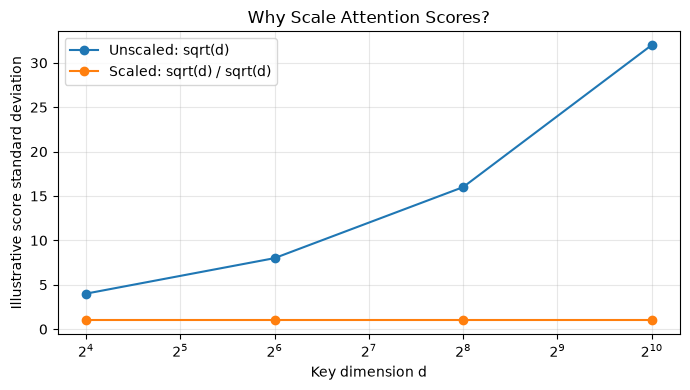

In [19]:
dimensions = np.array([16, 64, 256, 1024])
raw_std = np.sqrt(dimensions)
scaled_std = raw_std / np.sqrt(dimensions)

print("Dimension:", dimensions)
print("Approx. raw score standard deviation:", raw_std)
print("Approx. scaled score standard deviation:", scaled_std)

plt.figure(figsize=(7, 4))
plt.plot(dimensions, raw_std, marker="o", label="Unscaled: sqrt(d)")
plt.plot(dimensions, scaled_std, marker="o", label="Scaled: sqrt(d) / sqrt(d)")
plt.xscale("log", base=2)
plt.xlabel("Key dimension d")
plt.ylabel("Illustrative score standard deviation")
plt.title("Why Scale Attention Scores?")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Important:** This plot illustrates the variance intuition under simplified assumptions. Actual score distributions depend on model weights and inputs.

 
“Why divide by the square root of the dimension? As the dimension grows, raw dot-product scores can become larger. Large score differences can make Softmax focus too strongly on one position. Scaling helps keep the score range under control. It is a small formula change with an important effect.”

## 8. Context length and quadratic growth

A full attention score matrix has `sequence_length × sequence_length` entries. Doubling the sequence length makes the matrix four times as large.

Sequence length | Matrix entries | One-head FP16 matrix (MiB)
            512 |        262,144 |                    0.50
          1,024 |      1,048,576 |                    2.00
          2,048 |      4,194,304 |                    8.00
          4,096 |     16,777,216 |                   32.00
          8,192 |     67,108,864 |                  128.00
         16,384 |    268,435,456 |                  512.00


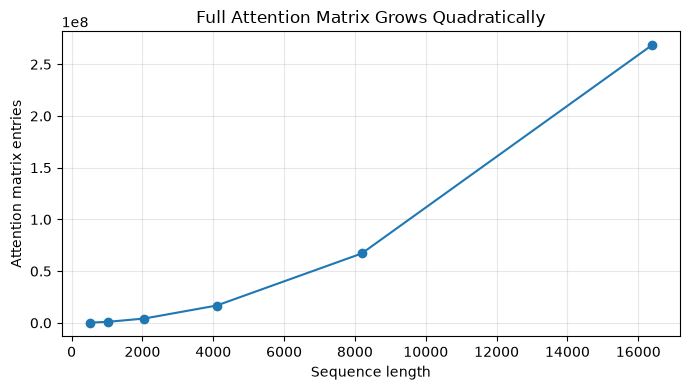

In [20]:
lengths = np.array([512, 1024, 2048, 4096, 8192, 16384])
matrix_entries = lengths ** 2
fp16_bytes = matrix_entries * 2  # 2 bytes per entry

print("Sequence length | Matrix entries | One-head FP16 matrix (MiB)")
for n, entries, size_bytes in zip(lengths, matrix_entries, fp16_bytes):
    print(f"{n:>15,} | {entries:>14,} | {size_bytes / (1024**2):>23.2f}")

plt.figure(figsize=(7, 4))
plt.plot(lengths, matrix_entries, marker="o")
plt.xlabel("Sequence length")
plt.ylabel("Attention matrix entries")
plt.title("Full Attention Matrix Grows Quadratically")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**What to notice:** The curve rises much faster as the sequence gets longer. This is why long context can be expensive.

  
“The full attention score matrix has one row and one column for every token. Its size grows with the square of the sequence length. If we double the number of tokens, the matrix becomes four times larger. FlashAttention reduces memory traffic by processing attention in tiles and avoiding storing the full score matrix in high-bandwidth memory. The exact attention calculation still has quadratic arithmetic cost.”

## 9. Mini experiment: change the context length

Change the value of `n` and run the cell again. Notice how the number of matrix entries changes.

In [21]:
n = 4096  # Try 1024, 2048, 4096, or 8192
entries = n * n
memory_mib = entries * 2 / (1024**2)  # one head, FP16, fully materialized matrix

print(f"Context length: {n:,} tokens")
print(f"Score matrix entries: {entries:,}")
print(f"Illustrative one-head FP16 matrix: {memory_mib:.2f} MiB")

Context length: 4,096 tokens
Score matrix entries: 16,777,216
Illustrative one-head FP16 matrix: 32.00 MiB



“Here is a small experiment. I can change the context length and run the cell again. Watch how quickly the number of score-matrix entries grows. This helps us understand why attention memory and performance matter in inference engineering.”

## 10. Quick knowledge check

Answer these before moving to the next day.

1. What is the role of Query?
2. Why do we apply Softmax to attention scores?
3. What does the causal mask block?
4. Which design uses one shared Key-Value head: MHA, GQA, or MQA?
5. If context length doubles, how does the full score-matrix size change?
6. Does FlashAttention make exact full attention linear in sequence length?

### Answers

1. Query represents the information a token is looking for.
2. Softmax converts scores into weights that sum to one per row.
3. It blocks future token positions.
4. MQA.
5. It becomes four times as large.
6. No. FlashAttention reduces memory traffic and avoids materializing the full matrix, but exact full attention still has quadratic arithmetic complexity.

## Day 04 summary

- Q, K, and V are the three projections used by attention.
- Attention scores compare Queries with Keys.
- Softmax turns scores into weights.
- Values are combined using those weights.
- Causal masking prevents future-token access.
- GQA and MQA reduce Key-Value cache requirements compared with MHA when they use fewer KV heads.
- Scaling by the square root of the key dimension helps control score magnitude.
- Full attention score-matrix size grows quadratically with sequence length.
- FlashAttention improves memory efficiency by reducing memory traffic.

**Next lesson:** Day 05 — KV Cache.